# Lecture 21, Weather generators

> Simulating long, realistic daily weather with a few fitted parameters, and changing those parameters to represent a future climate

Lectures 18 to 20 corrected or regressed the *output* of a climate model. A **stochastic weather generator** (WG) takes a different route. It is a small statistical model of the *observed* daily weather at one site. Once its parameters are fitted, it can produce as many years of synthetic daily rainfall, temperature and radiation as we like, with the same statistics as the record. This is useful for two reasons:

- **A 30-year record is short.** A flood, drought or crop-failure risk analysis needs hundreds of years of plausible weather, so that rare combinations (a long dry spell followed by an intense storm) are sampled, not just the ones that happened to occur.
- **It is a downscaling tool.** The generator's parameters (how often it rains, how much, how warm) can be *perturbed* by the change factors of a GCM or RCM. The output is then a long daily series for a future climate at the station scale, including changes in the *frequency* and *persistence* of rain that a simple delta change (Lecture 14, Section 4) cannot produce.

By the end of this lecture you should be able to:

- derive the mean, variance and autocorrelation of an **AR(1)** process and fit it to data, and extend it to the **multivariate AR(1)** for Tmax, Tmin and solar radiation, using the Cholesky factor to simulate correlated noise,
- derive the **two-state Markov chain** for rainfall occurrence: its maximum-likelihood parameters, stationary wet-day probability and the geometric spell lengths it implies,
- combine occurrence, gamma amounts and the multivariate AR(1) into a **WGEN-style generator** with monthly parameters and harmonics,
- **validate** a generator, and recognise its well-known weakness (too little year-to-year variability),
- apply **change factors** to the parameters and read off the effect on wet spells, annual totals and extremes,
- describe the **k-nearest-neighbour** (nonparametric) generator and its strengths and limits.

**Data.** All data in this lecture are **synthetic**. The "observed" daily series (30 years, 365 days each, Tmax, Tmin, solar radiation, rain) was produced by a seasonal stochastic model with a monsoon-type cycle, so that the lecture is reproducible offline; it is not a measurement from any station. To use a real station, replace the file `data/downscaling/lec21/obs_daily_synthetic.csv` (columns `day, year, doy, month, rain_mm, tmax_c, tmin_c, srad_mjm2`, 365-day years) and rerun every cell. A companion Excel workbook, `data/downscaling/lec21/lec21_worked_examples.xlsx`, repeats the main calculations with live formulas (Section 9).

The method follows Lee and Singh (2019), Chapter 6; the derivations and examples are our own.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy scipy pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma as gamma_dist, norm

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

BASE = "data/downscaling/lec21/"
URL = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec21/"


def read(name):
    try:
        return pd.read_csv(BASE + name)
    except FileNotFoundError:          # e.g. on Colab without the repository
        return pd.read_csv(URL + name)


obs = read("obs_daily_synthetic.csv")      # SYNTHETIC "observed" record, 30 years x 365 days
uni = read("fixed_uniforms.csv")           # fixed uniform random numbers (also stored in the Excel workbook)

MD = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])        # days per month (no 29 February)
MSTART = np.concatenate([[1], 1 + np.cumsum(MD)[:-1]])                 # first day of each month
OMEGA = 2 * np.pi / 365                                                # annual angular frequency [rad/day]
VARS = ["tmax_c", "tmin_c", "srad_mjm2"]
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

month, doy, rain = obs["month"].to_numpy(), obs["doy"].to_numpy(), obs["rain_mm"].to_numpy()
wet = (rain >= 0.1).astype(int)            # a wet day has at least 0.1 mm
print(f"{len(obs)} days = {len(obs)//365} years;  wet-day fraction {wet.mean():.3f};  mean annual rain {rain.sum()/30:.0f} mm")
obs.head()

10950 days = 30 years;  wet-day fraction 0.221;  mean annual rain 1007 mm


,day,year,doy,month,rain_mm,tmax_c,tmin_c,srad_mjm2
0,1,1,1,1,9.7,27.9,14.9,9.04
1,2,1,2,1,0.0,30.9,14.5,12.15
2,3,1,3,1,0.0,32.8,14.2,18.03
3,4,1,4,1,0.0,32.7,13.4,18.58
4,5,1,5,1,0.0,31.5,13.0,16.59


# 1) What a weather generator is, and why it is downscaling

A weather generator is a *recipe for random weather*. Every day it draws

1. **whether it rains** (occurrence),
2. **how much** it rains, if it does (amount),
3. **temperature and solar radiation**, which depend on the season and on whether it is wet or dry,

so that the long-run statistics match the station record. The parameters are estimated from the observations, separately for each month or season, so the model has the seasonal cycle of a monsoon climate built in.

```
observed daily record  --fit-->  parameters (per month)  --simulate-->  100 years of synthetic daily weather
                                        |
              GCM/RCM change factors  --perturb-->  parameters of a future climate  --simulate-->  future weather
```

Why is the last arrow downscaling? A GCM is reliable (relatively) for the *change* in monthly mean rainfall or temperature, not for the day-to-day sequence. The generator supplies the day-to-day sequence and the local statistics; the GCM supplies only the change. This is the same *delta* idea as Lecture 14, but applied to **model parameters** instead of to observed values, so we can change not only the mean but also the wet-day frequency, the persistence of wet and dry spells and the intensity of rainfall. The price is that the generator is only as good as its assumptions (Section 7 tests them), and the changes in its parameters must be chosen with care.

The rest of the lecture builds the generator in the order in which it runs: first the time-series tools (AR(1) and its multivariate form, for temperature), then the Markov chain (for rain occurrence), the gamma distribution (for rain amount), the assembled generator, validation, the change-factor step and finally a nonparametric alternative.

# 2) The AR(1) model, derived

Daily temperature is **persistent**: a hot day is more likely to be followed by a hot day than by a cold one. The simplest model of persistence is the first-order autoregression. Let $a_t$ be the *anomaly* (the value minus its seasonal mean, so the mean is zero) on day $t$:

$$a_t = \phi\, a_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim N(0,\sigma_\varepsilon^{2}) \text{ independent of everything before day } t.$$

Here $\phi$ is the dimensionless persistence parameter ($|\phi|<1$ for a stationary process) and $\sigma_\varepsilon$ [same unit as $a$, for example $^\circ$C] is the standard deviation of the daily "innovation", the fresh random part that the previous day does not explain.

**Mean.** Take expectations: $E[a_t] = \phi E[a_{t-1}] + 0$. In a stationary process $E[a_t]=E[a_{t-1}]$, so $(1-\phi)E[a]=0$ and $E[a]=0$.

**Variance.** Take the variance of both sides. Because $\varepsilon_t$ is independent of $a_{t-1}$ the cross term vanishes:

$$\operatorname{Var}(a_t) = \phi^{2}\operatorname{Var}(a_{t-1}) + \sigma_\varepsilon^{2}.$$

In the stationary state $\operatorname{Var}(a_t)=\operatorname{Var}(a_{t-1})=\sigma_a^{2}$, so $\sigma_a^{2}(1-\phi^{2})=\sigma_\varepsilon^{2}$:

$$\boxed{\;\sigma_a^{2}=\frac{\sigma_\varepsilon^{2}}{1-\phi^{2}}\;}$$

The variance of the series is *larger* than the variance of the noise, increasingly so as $\phi\to1$: persistence lets the noise accumulate.

**Autocorrelation.** Multiply the model by $a_{t-1}$ and take expectations: $\operatorname{Cov}(a_t,a_{t-1}) = \phi\,\sigma_a^{2}+0$, so the lag-1 autocorrelation is $\rho_1=\phi$. Repeating with $a_{t-k}$ gives $\operatorname{Cov}(a_t,a_{t-k}) = \phi\operatorname{Cov}(a_{t-1},a_{t-k})$ and by induction

$$\boxed{\;\rho_k=\phi^{k}\;}$$

so the memory decays geometrically, with an e-folding time of $-1/\ln\phi$ days.

**Estimation.** From the two boxed results: $\hat\phi$ is the sample lag-1 autocorrelation (this is the Yule&ndash;Walker estimate for $p=1$), $\hat\sigma_a$ is the sample standard deviation, and $\hat\sigma_\varepsilon^{2}=\hat\sigma_a^{2}(1-\hat\phi^{2})$. To **simulate**, draw $z_t\sim N(0,1)$ and set $a_t=\phi a_{t-1}+\sigma_\varepsilon z_t$; this is exactly why the innovation, not the total, standard deviation appears in the recursion.

*Numerical check.* $\phi=0.7$ and $\sigma_a=2\,^\circ$C give $\sigma_\varepsilon^{2}=4(1-0.49)=2.04$ $^\circ$C$^2$, $\rho_1=0.7$, $\rho_2=0.49$ and an e-folding time $-1/\ln 0.7\approx2.8$ days. The cell below tests this by simulation.

sigma_e^2 = 2.040  ->  simulated variance 3.965  (theory sigma_a^2 = 4.000)
lag  simulated  theory phi^k
  1      0.698      0.700
  2      0.486      0.490
  3      0.342      0.343
  5      0.167      0.168


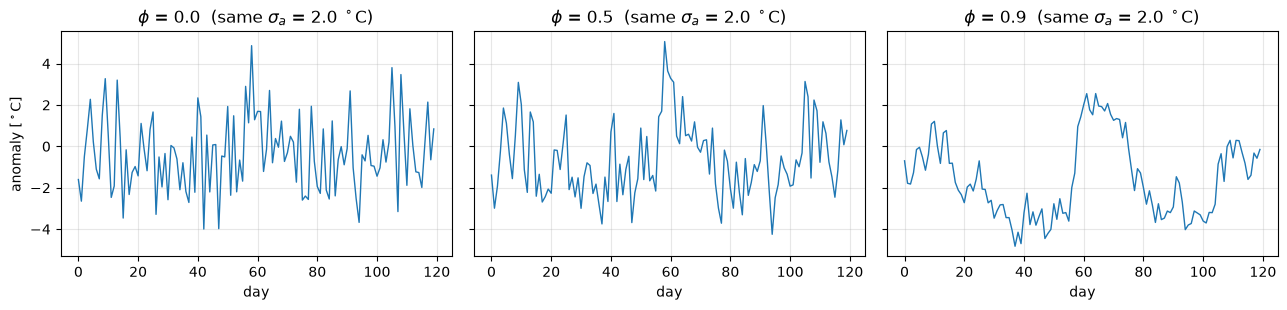

In [3]:
rng = np.random.default_rng(1)
phi, sig_a = 0.7, 2.0
sig_e = sig_a * np.sqrt(1 - phi**2)          # innovation sd from the stationary variance formula


def ar1(phi, sig_e, n, z):
    a = np.zeros(n); prev = 0.0
    for t in range(n):
        prev = phi * prev + sig_e * z[t]
        a[t] = prev
    return a


n = 200_000
a = ar1(phi, sig_e, n, rng.standard_normal(n))[1000:]          # drop a short spin-up
acf = lambda x, k: np.corrcoef(x[k:], x[:-k])[0, 1]
print(f"sigma_e^2 = {sig_e**2:.3f}  ->  simulated variance {a.var():.3f}  (theory sigma_a^2 = {sig_a**2:.3f})")
print("lag  simulated  theory phi^k")
for k in (1, 2, 3, 5):
    print(f"{k:>3}  {acf(a, k):9.3f}  {phi**k:9.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, ph in zip(axes, (0.0, 0.5, 0.9)):
    z = np.random.default_rng(5).standard_normal(120)
    ax.plot(ar1(ph, sig_a * np.sqrt(1 - ph**2), 120, z), lw=1)
    ax.set_title(f"$\\phi$ = {ph}  (same $\\sigma_a$ = {sig_a} $^\\circ$C)"); ax.set_xlabel("day")
axes[0].set_ylabel("anomaly [$^\\circ$C]")
fig.tight_layout();

phi = 0.547, sigma_a = 2.29 C, innovation sd = 1.91 C, e-folding time = 1.7 d


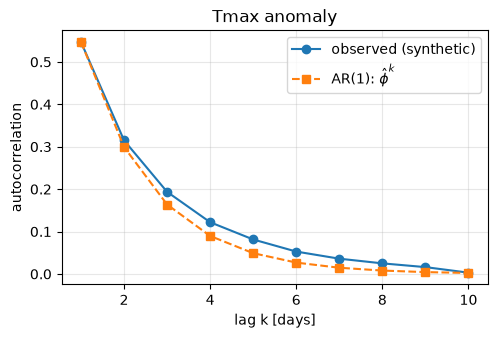

In [4]:
# Fit an AR(1) to the Tmax anomaly of the synthetic record (anomaly = value minus seasonal harmonic).
def harmonic_fit(x, doy):
    """Mean and first-harmonic coefficients (exact least squares over whole years)."""
    n = len(x)
    return x.mean(), 2 * np.sum(x * np.cos(OMEGA * doy)) / n, 2 * np.sum(x * np.sin(OMEGA * doy)) / n


def harmonic(coef, doy):
    return coef[0] + coef[1] * np.cos(OMEGA * doy) + coef[2] * np.sin(OMEGA * doy)


c_tmax = harmonic_fit(obs["tmax_c"].to_numpy(), doy)
an = obs["tmax_c"].to_numpy() - harmonic(c_tmax, doy)
phi_hat, sig_hat = np.corrcoef(an[1:], an[:-1])[0, 1], an.std(ddof=1)
sig_e_hat = sig_hat * np.sqrt(1 - phi_hat**2)
print(f"phi = {phi_hat:.3f}, sigma_a = {sig_hat:.2f} C, innovation sd = {sig_e_hat:.2f} C, e-folding time = {-1/np.log(phi_hat):.1f} d")

lags = np.arange(1, 11)
plt.figure(figsize=(5.5, 3.3))
plt.plot(lags, [acf(an, k) for k in lags], "o-", label="observed (synthetic)")
plt.plot(lags, phi_hat ** lags, "s--", label="AR(1): $\\hat\\phi^{k}$")
plt.xlabel("lag k [days]"); plt.ylabel("autocorrelation"); plt.title("Tmax anomaly"); plt.legend();

**How good is AR(1) here?** The observed autocorrelation falls a little more slowly than $\hat\phi^{k}$ because part of the memory comes from wet and dry *spells* (a wet spell keeps Tmax low for several days), which the plain AR(1) does not know about. The generator below conditions temperature on the wet or dry state, which captures part of this.

# 3) The multivariate AR(1): Tmax, Tmin and solar radiation together

Tmax, Tmin and solar radiation are correlated on the same day (a cloudy day has low radiation, a low Tmax and a smaller diurnal range) *and* each is persistent. We stack the three standardised anomalies into a vector $\mathbf y_t=(y_{1},y_{2},y_{3})^{T}$ (mean zero, unit variance, see Section 6) and write

$$\mathbf y_t=\mathbf A\,\mathbf y_{t-1}+\mathbf B\,\mathbf e_t,\qquad \mathbf e_t\sim N(\mathbf 0,\mathbf I),$$

where $\mathbf A$ is a $3\times3$ matrix of day-to-day coupling (its diagonal is the persistence of each variable, its off-diagonal terms say how yesterday's Tmax influences today's Tmin and so on) and $\mathbf B$ is a $3\times3$ matrix that shapes the noise. Define the **lag-0 and lag-1 covariance matrices**

$$\mathbf M_0=E[\mathbf y_t\mathbf y_t^{T}],\qquad \mathbf M_1=E[\mathbf y_t\mathbf y_{t-1}^{T}].$$

The element $(i,j)$ of $\mathbf M_0$ is the same-day correlation between variables $i$ and $j$; of $\mathbf M_1$ it is the correlation of variable $i$ today with variable $j$ yesterday.

**Finding $\mathbf A$.** Multiply the model on the right by $\mathbf y_{t-1}^{T}$ and take expectations. The new noise $\mathbf e_t$ is independent of $\mathbf y_{t-1}$, so
$\mathbf M_1=\mathbf A\mathbf M_0$ and

$$\boxed{\;\mathbf A=\mathbf M_1\mathbf M_0^{-1}\;}$$

**Finding $\mathbf B$.** Multiply on the right by $\mathbf y_t^{T}$ instead. Using $E[\mathbf y_{t-1}\mathbf y_t^{T}]=\mathbf M_1^{T}$ and $E[\mathbf e_t\mathbf y_t^{T}]=\mathbf B^{T}$ (because $\mathbf y_t$ contains $\mathbf B\mathbf e_t$),

$$\mathbf M_0=\mathbf A\mathbf M_1^{T}+\mathbf B\mathbf B^{T}\quad\Longrightarrow\quad \boxed{\;\mathbf B\mathbf B^{T}=\mathbf D\equiv\mathbf M_0-\mathbf A\mathbf M_1^{T}\;}$$

(since $\mathbf M_1=\mathbf A\mathbf M_0$ this equals $\mathbf M_0-\mathbf A\mathbf M_0\mathbf A^{T}$, the multivariate counterpart of $\sigma_a^2(1-\phi^2)=\sigma_\varepsilon^2$.) *Scalar check:* with one variable, $M_0=1$ and $M_1=\phi$, so $A=\phi$ and $BB^{T}=1-\phi^{2}$, which is the AR(1) result.

**Why the Cholesky factor.** $\mathbf D$ is the covariance of the *noise* $\mathbf B\mathbf e_t$, which is correlated across the three variables. We need a matrix $\mathbf B$ with $\mathbf B\mathbf B^{T}=\mathbf D$; then independent standard normals $\mathbf e_t$ give $\operatorname{Cov}(\mathbf B\mathbf e_t)=\mathbf B\mathbf I\mathbf B^{T}=\mathbf D$. The lower-triangular choice (the **Cholesky factor**) exists whenever $\mathbf D$ is positive definite and is found by simple recursion. For three variables:

$$b_{11}=\sqrt{d_{11}},\quad b_{21}=\frac{d_{21}}{b_{11}},\quad b_{22}=\sqrt{d_{22}-b_{21}^{2}},\quad b_{31}=\frac{d_{31}}{b_{11}},\quad b_{32}=\frac{d_{32}-b_{31}b_{21}}{b_{22}},\quad b_{33}=\sqrt{d_{33}-b_{31}^{2}-b_{32}^{2}}.$$

Reading the first column: the first variable gets its own noise; the second gets the part correlated with the first plus fresh noise; and so on. In code we simply call `np.linalg.cholesky`.

The cell below builds a made-up three-variable process, simulates it for a long time and recovers $\mathbf A$ and $\mathbf B$ from the sample $\mathbf M_0,\mathbf M_1$, which is exactly what the generator does with the observations.

In [5]:
A_true = np.array([[0.55, 0.10, 0.05], [0.12, 0.50, 0.00], [0.05, 0.00, 0.35]])
M0_true = np.array([[1.0, 0.60, 0.25], [0.60, 1.0, 0.10], [0.25, 0.10, 1.0]])   # Tmax, Tmin, Srad
D_true = M0_true - A_true @ M0_true @ A_true.T
B_true = np.linalg.cholesky(D_true)
print("Cholesky factor B (lower triangular):\n", B_true.round(3))
print("B B^T equals D:", np.allclose(B_true @ B_true.T, D_true))

rng = np.random.default_rng(3)
n = 100_000
E = rng.standard_normal((n, 3))
Y = np.zeros((n, 3)); y = np.zeros(3)
for t in range(n):
    y = A_true @ y + B_true @ E[t]
    Y[t] = y

M0_hat = Y.T @ Y / n                       # sample lag-0 covariance
M1_hat = Y[1:].T @ Y[:-1] / (n - 1)        # sample lag-1 covariance
A_hat = M1_hat @ np.linalg.inv(M0_hat)
D_hat = M0_hat - A_hat @ M1_hat.T
B_hat = np.linalg.cholesky(D_hat)
print("\nmax |M0_hat - M0_true| =", np.abs(M0_hat - M0_true).max().round(3))
print("max |A_hat  - A_true | =", np.abs(A_hat - A_true).max().round(3))
print("max |B_hat  - B_true | =", np.abs(B_hat - B_true).max().round(3))
print("noise covariance B e (sample) vs D:\n", np.cov((E @ B_true.T).T).round(2), "\n", D_true.round(2))

Cholesky factor B (lower triangular):
 [[ 0.777  0.     0.   ]
 [ 0.396  0.712  0.   ]
 [ 0.193 -0.036  0.91 ]]
B B^T equals D: True



max |M0_hat - M0_true| = 0.006
max |A_hat  - A_true | = 0.003
max |B_hat  - B_true | = 0.004


noise covariance B e (sample) vs D:
 [[0.6  0.31 0.15]
 [0.31 0.66 0.05]
 [0.15 0.05 0.87]] 
 [[0.6  0.31 0.15]
 [0.31 0.66 0.05]
 [0.15 0.05 0.87]]


# 4) The Markov chain for rainfall occurrence, derived

Rain is not Gaussian and it is intermittent, so occurrence and amount are modelled separately. Let $X_t=1$ if day $t$ is wet and $X_t=0$ if it is dry. A **first-order Markov chain** says that the chance of rain today depends on yesterday's state only:

$$P(X_t=j\mid X_{t-1}=i,X_{t-2},\dots)=P(X_t=j\mid X_{t-1}=i)=P_{ij}.$$

With two states there are two free numbers, because rows add to one:

$$\mathbf P=\begin{pmatrix}P_{00}&P_{01}\\P_{10}&P_{11}\end{pmatrix}=\begin{pmatrix}1-P_{01}&P_{01}\\1-P_{11}&P_{11}\end{pmatrix},$$

$P_{01}$ is the probability that a dry day is followed by a wet day, $P_{11}$ that a wet day is followed by a wet day (both dimensionless).

**Maximum-likelihood estimates.** Let $N_{ij}$ be the number of days in the record on which the chain moved from state $i$ to state $j$, and $N_i=N_{i0}+N_{i1}$ the number of days (with a successor) that were in state $i$. Given the first day, the probability of the whole record is the product of one transition probability per day, so

$$L=P_{01}^{N_{01}}(1-P_{01})^{N_{00}}\,P_{11}^{N_{11}}(1-P_{11})^{N_{10}},\qquad \ln L=N_{01}\ln P_{01}+N_{00}\ln(1-P_{01})+N_{11}\ln P_{11}+N_{10}\ln(1-P_{11}).$$

The two parameters appear in separate terms, so they are maximised separately. Setting $\partial\ln L/\partial P_{01}=N_{01}/P_{01}-N_{00}/(1-P_{01})=0$ gives

$$\boxed{\;\hat P_{01}=\frac{N_{01}}{N_{00}+N_{01}}=\frac{N_{01}}{N_0},\qquad \hat P_{11}=\frac{N_{11}}{N_{10}+N_{11}}=\frac{N_{11}}{N_1}\;}$$

the observed fraction of dry (wet) days that were followed by a wet day. This is the "counts to transition matrix" step of the spreadsheet. In a monsoon climate the probabilities change with the season, so the counts are made **separately for each month**, attributing each transition to the month of the day on which it ends.

**Stationary wet-day probability.** In the long run the state probabilities $\boldsymbol\pi=(\pi_0,\pi_1)$ no longer change: $\boldsymbol\pi=\boldsymbol\pi\mathbf P$. The wet component gives $\pi_1=\pi_0P_{01}+\pi_1P_{11}$; substituting $\pi_0=1-\pi_1$,

$$\pi_1(1-P_{11})=(1-\pi_1)P_{01}\quad\Longrightarrow\quad\boxed{\;\pi_1=\frac{P_{01}}{P_{01}+1-P_{11}}\;}$$

It is convenient to define the **persistence** $\gamma=P_{11}-P_{01}$, the lag-1 autocorrelation of the occurrence series (the same role as $\phi$ in AR(1)). Then $\pi_1=P_{01}/(1-\gamma)$, so $P_{01}=\pi_1(1-\gamma)$ and $P_{11}=\pi_1(1-\gamma)+\gamma$. This is the form used for change factors in Section 8: wet-day frequency and persistence are the two natural handles.

**Spell lengths.** A wet spell starts and then continues each further day with probability $P_{11}$ and ends with probability $1-P_{11}$. The chance that it lasts exactly $k$ days is therefore

$$P(L_{\text{wet}}=k)=P_{11}^{\,k-1}(1-P_{11}),\qquad k=1,2,\dots$$

a **geometric distribution**. Its mean is $E[L_{\text{wet}}]=\sum_k kP_{11}^{k-1}(1-P_{11})=\dfrac{1}{1-P_{11}}$, and likewise $E[L_{\text{dry}}]=1/P_{01}$. *Consistency check:* the long-run wet fraction must be the mean wet spell divided by a mean wet-plus-dry cycle,
$\dfrac{1/(1-P_{11})}{1/(1-P_{11})+1/P_{01}}=\dfrac{P_{01}}{P_{01}+1-P_{11}}=\pi_1$. With $P_{01}=0.25$ and $P_{11}=0.60$: $\pi_1=0.385$, wet spells average $2.5$ days, dry spells $4.0$ days, and $2.5/6.5=0.385$.

**The weakness built in.** The geometric distribution is *memoryless*: a spell that has lasted ten days is as likely to end tomorrow as one that has lasted two. Real spells are often more variable, with more very short and very long ones than a geometric law allows. Two standard remedies are (i) a **higher-order chain**, in which today depends on the last two or three days (four or eight states, so more parameters per month), and (ii) a **mixed or alternating-renewal model** in which spell lengths are drawn directly from a flexible distribution, for example a mixture of two geometrics, at the cost of losing the one-line Markov formulation. For monsoon rain, where a wet or dry "break" spell can last weeks, this is a real issue, and validation of the spell-length distribution (Section 7) is therefore essential.

**Simulation** uses a uniform random number $u$ (Lecture 17, inverse transform): the day is wet if $u<P_{1\mid\text{yesterday}}$, that is $u<P_{11}$ after a wet day and $u<P_{01}$ after a dry day.

In [6]:
def fit_occurrence(month, wet):
    """Monthly counts N0, N01, N1, N11 (transition attributed to the month of the CURRENT day) and P01, P11."""
    prev, cur, m = wet[:-1], wet[1:], month[1:]
    out = {}
    for k in range(1, 13):
        s = m == k
        N0, N1 = np.sum(s & (prev == 0)), np.sum(s & (prev == 1))
        N01, N11 = np.sum(s & (prev == 0) & (cur == 1)), np.sum(s & (prev == 1) & (cur == 1))
        out[k] = dict(N0=N0, N01=N01, N1=N1, N11=N11, P01=N01 / N0, P11=N11 / N1)
    P01 = np.array([out[k]["P01"] for k in range(1, 13)]); P11 = np.array([out[k]["P11"] for k in range(1, 13)])
    return P01, P11, out


def stationary_wet(P01, P11):
    return P01 / (1 + P01 - P11)


P01, P11, counts = fit_occurrence(month, wet)
j = 7                                                          # July
c = counts[j]
print("July counts:  N00 =", c["N0"] - c["N01"], " N01 =", c["N01"], " N10 =", c["N1"] - c["N11"], " N11 =", c["N11"])
Pm = np.array([[1 - P01[j-1], P01[j-1]], [1 - P11[j-1], P11[j-1]]])
pi1 = stationary_wet(P01[j-1], P11[j-1])
print("transition matrix (rows: yesterday dry, wet):\n", Pm.round(3))
print(f"stationary wet probability {pi1:.3f};  observed July wet fraction {wet[month == j].mean():.3f}")
print("check  pi P = pi :", (np.array([1 - pi1, pi1]) @ Pm).round(4), " vs ", np.array([1 - pi1, pi1]).round(4))
print(f"expected wet spell {1/(1-P11[j-1]):.2f} d,  expected dry spell {1/P01[j-1]:.2f} d")

July counts:  N00 = 211  N01 = 128  N10 = 120  N11 = 471
transition matrix (rows: yesterday dry, wet):
 [[0.622 0.378]
 [0.203 0.797]]
stationary wet probability 0.650;  observed July wet fraction 0.644
check  pi P = pi : [0.3497 0.6503]  vs  [0.3497 0.6503]
expected wet spell 4.92 d,  expected dry spell 2.65 d


observed mean wet spell 4.47 d (chain 4.92);  dry 2.45 d (chain 2.65)


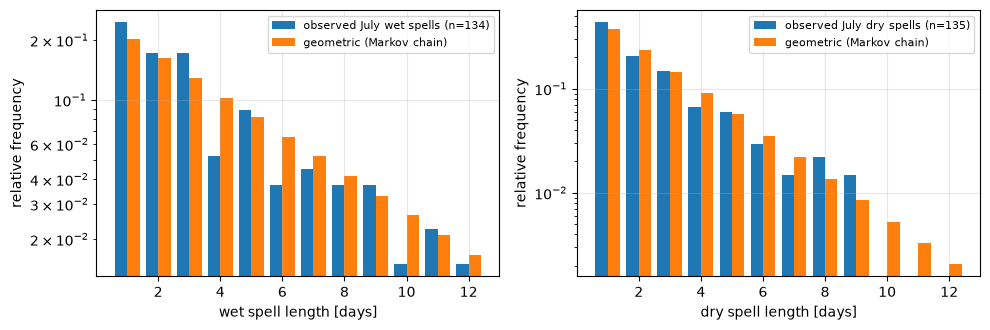

In [7]:
def spells(wet):
    """Lengths of wet and dry spells (runs of 1s and 0s) in a 0/1 series."""
    w = np.asarray(wet)
    edge = np.flatnonzero(np.diff(w)) + 1
    runs = np.split(w, edge)
    wl = np.array([len(r) for r in runs if r[0] == 1]); dl = np.array([len(r) for r in runs if r[0] == 0])
    return wl, dl


# spells that lie inside July of each year (they are cut at the month edges, which removes a few long ones)
wl, dl = [], []
for yr in obs["year"].unique():
    s = (obs["year"].to_numpy() == yr) & (month == j)
    a_, b_ = spells(wet[s]); wl += list(a_); dl += list(b_)
wl, dl = np.array(wl), np.array(dl)
k = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, L_, p, nm in ((axes[0], wl, P11[j-1], "wet"), (axes[1], dl, 1 - P01[j-1], "dry")):
    ax.bar(k - 0.2, [np.mean(L_ == i) for i in k], width=0.4, label=f"observed July {nm} spells (n={len(L_)})")
    pmf = p ** (k - 1) * (1 - p)
    ax.bar(k + 0.2, pmf, width=0.4, label="geometric (Markov chain)")
    ax.set_yscale("log"); ax.set_xlabel(f"{nm} spell length [days]"); ax.set_ylabel("relative frequency"); ax.legend(fontsize=8)
fig.tight_layout()
print(f"observed mean wet spell {wl.mean():.2f} d (chain {1/(1-P11[j-1]):.2f});  dry {dl.mean():.2f} d (chain {1/P01[j-1]:.2f})")

In the synthetic record the chain was by construction a good description, apart from the interannual modulation built into the data, so the match is close. With a real record, differences in the tail of the dry-spell distribution are the first thing to look for.

# 5) Rainfall amounts on wet days: the gamma distribution

On a wet day the amount is positive and right-skewed: many light falls and a few heavy ones. The **gamma distribution** (Lecture 17) is the standard choice. With shape $\alpha$ [-] and scale $\beta$ [mm],

$$f(x)=\frac{x^{\alpha-1}e^{-x/\beta}}{\Gamma(\alpha)\,\beta^{\alpha}},\quad x>0,\qquad E[X]=\alpha\beta,\qquad \operatorname{Var}(X)=\alpha\beta^{2}.$$

Solving the last two for the parameters gives the **method of moments**, with $\bar x$ and $s^{2}$ the mean and variance of the wet-day amounts of the month:

$$\hat\alpha=\frac{\bar x^{2}}{s^{2}},\qquad \hat\beta=\frac{s^{2}}{\bar x}.$$

(Maximum likelihood, Lecture 17, is slightly better for small samples but needs a numerical solver; moments are what the spreadsheet uses.) For $\alpha=1$ the gamma becomes the **exponential** distribution; for $\alpha<1$ the density is highest at zero and the tail is long, which is typical of daily rainfall. *Numerical check:* a month with mean $12$ mm and standard deviation $14$ mm per wet day has $\hat\alpha=144/196=0.73$ and $\hat\beta=196/12=16.3$ mm, and $\alpha\beta=11.9$ mm, as it should.

A random amount is drawn by **inverse-transform sampling**: $x=F^{-1}(u;\alpha,\beta)$ for a uniform $u$, in Python `gamma_dist.ppf(u, alpha, scale=beta)` and in Excel `GAMMA.INV(u, alpha, beta)`. The parameters are estimated **month by month**, so the monsoon months have a larger scale than the winter months.

shape alpha by month: [0.93 0.52 0.98 0.91 0.84 0.8  0.89 0.77 0.8  0.66 0.67 1.21]
scale beta by month [mm]: [ 3.6  7.5  4.5  6.7 11.  17.1 17.2 19.8 15.7 10.7 10.3  4.5]


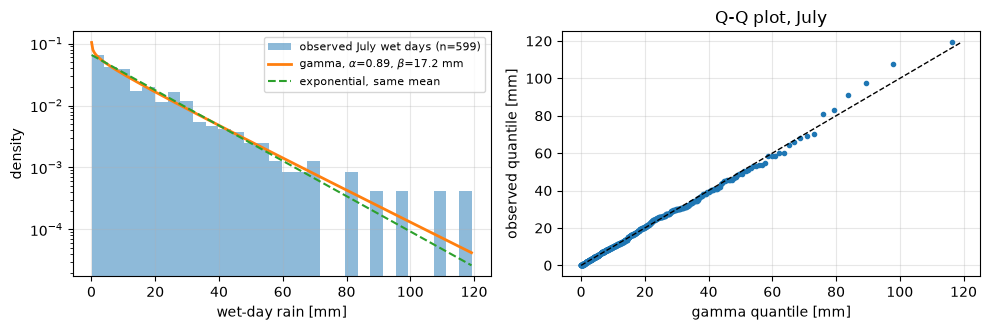

In [8]:
def fit_gamma(month, rain, wet):
    """Method of moments for the wet-day amounts of each month: mean, variance (n-1), shape, scale."""
    mean = np.array([rain[(month == k) & (wet == 1)].mean() for k in range(1, 13)])
    var = np.array([rain[(month == k) & (wet == 1)].var(ddof=1) for k in range(1, 13)])
    return mean, var, mean ** 2 / var, var / mean


g_mean, g_var, alpha, beta = fit_gamma(month, rain, wet)
x = rain[(month == j) & (wet == 1)]
xx = np.linspace(0.05, x.max(), 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(x, bins=30, density=True, alpha=0.5, label=f"observed July wet days (n={len(x)})")
axes[0].plot(xx, gamma_dist.pdf(xx, alpha[j-1], scale=beta[j-1]), lw=2, label=f"gamma, $\\alpha$={alpha[j-1]:.2f}, $\\beta$={beta[j-1]:.1f} mm")
axes[0].plot(xx, np.exp(-xx / x.mean()) / x.mean(), "--", label="exponential, same mean")
axes[0].set_yscale("log"); axes[0].set_xlabel("wet-day rain [mm]"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
q = (np.arange(1, len(x) + 1) - 0.5) / len(x)
axes[1].plot(gamma_dist.ppf(q, alpha[j-1], scale=beta[j-1]), np.sort(x), ".")
axes[1].plot([0, x.max()], [0, x.max()], "k--", lw=1)
axes[1].set_xlabel("gamma quantile [mm]"); axes[1].set_ylabel("observed quantile [mm]"); axes[1].set_title("Q-Q plot, July")
fig.tight_layout()
print("shape alpha by month:", alpha.round(2))
print("scale beta by month [mm]:", beta.round(1))

# 6) The assembled generator (WGEN-style)

The classical WGEN generator of Richardson (1981) and Richardson and Wright (1984) runs the three parts in a fixed order, because temperature and radiation depend on the rain state but not the other way round:

1. **Occurrence.** Draw wet or dry from the Markov chain with the $P_{01},P_{11}$ of the current month.
2. **Amount.** If wet, draw the amount from the gamma distribution with the $\alpha,\beta$ of the current month.
3. **Temperature and radiation.** Draw $\mathbf y_t$ from the multivariate AR(1) (Section 3) and convert it to physical units with a mean and standard deviation that depend on the **day of the year** and on the **wet or dry state of the day**.

**Seasonality.** The rainfall parameters are monthly. For the slowly varying mean of temperature and radiation a monthly table would jump at month boundaries, so the mean is described by one harmonic:

$$\bar x(d)=\mu+a\cos(\omega d)+b\sin(\omega d)=\mu+C\cos\big(\omega(d-d_0)\big),\qquad \omega=\frac{2\pi}{365}\ \text{rad day}^{-1}.$$

Here $d$ is the day of the year, $C=\sqrt{a^{2}+b^{2}}$ the amplitude and $d_0$ the day of the maximum. Over whole years $\cos$ and $\sin$ are orthogonal, so least squares gives simply $\mu=\overline{x}$, $a=\tfrac{2}{N}\sum x\cos(\omega d)$, $b=\tfrac{2}{N}\sum x\sin(\omega d)$. The anomaly $x-\bar x(d)$ is then split into wet days and dry days, each with its own mean shift $\delta_s$ (a wet day is cooler and darker) and standard deviation $s_s$, $s\in\{\text{wet},\text{dry}\}$, and standardised,

$$y_t=\frac{x_t-\bar x(d_t)-\delta_{s_t}}{s_{s_t}}.$$

The three series $y$ are then used to estimate $\mathbf M_0,\mathbf M_1,\mathbf A,\mathbf B$. A simulated value is reconstructed as $x_t=\bar x(d_t)+\delta_{s_t}+s_{s_t}y_t$ using the state of the *simulated* day. (Lee and Singh also allow a harmonic for the standard deviation and the shifts; we keep them constant to keep the number of parameters small.)

The whole generator therefore has, per month, $P_{01},P_{11},\alpha,\beta$ (4 numbers), and for the three weather variables $3\times3$ harmonic coefficients, $3\times4$ wet/dry shifts and standard deviations, and the matrices $\mathbf A$ and $\mathbf B$ (18 numbers): about 100 parameters for a full station.

In [9]:
def fit_temperature(obs, wet):
    """Harmonic mean, wet/dry shift and sd of the anomaly, then M0, M1, A = M1 M0^-1, D = M0 - A M1^T, B = chol(D)."""
    doy = obs["doy"].to_numpy()
    coefs, shift, sd, Y = [], [], [], []
    for v in VARS:
        x = obs[v].to_numpy()
        c = harmonic_fit(x, doy)
        an = x - harmonic(c, doy)
        sh = [an[wet == 1].mean(), an[wet == 0].mean()]                 # [wet, dry]
        s = [an[wet == 1].std(ddof=1), an[wet == 0].std(ddof=1)]
        y = np.where(wet == 1, (an - sh[0]) / s[0], (an - sh[1]) / s[1])
        coefs.append(c); shift.append(sh); sd.append(s); Y.append(y)
    Y = np.array(Y)                                                     # 3 x N
    N = Y.shape[1]
    M0 = Y @ Y.T / N
    M1 = Y[:, 1:] @ Y[:, :-1].T / (N - 1)
    A = M1 @ np.linalg.inv(M0)
    D = M0 - A @ M1.T
    B = np.linalg.cholesky(D)
    return dict(coefs=np.array(coefs), shift=np.array(shift), sd=np.array(sd), M0=M0, M1=M1, A=A, D=D, B=B, y=Y)


tf = fit_temperature(obs, wet)
par = dict(P01=P01, P11=P11, alpha=alpha, beta=beta, tf=tf)

tab = pd.DataFrame({"P01": P01, "P11": P11, "P1 (stationary)": stationary_wet(P01, P11), "wet spell [d]": 1 / (1 - P11),
                    "dry spell [d]": 1 / P01, "mean wet-day rain [mm]": g_mean, "alpha": alpha, "beta [mm]": beta},
                   index=[f"{i}" for i in range(1, 13)]).round(3)
tab.index.name = "month"
display(tab)

names = ["Tmax", "Tmin", "Srad"]
amp = np.hypot(tf["coefs"][:, 1], tf["coefs"][:, 2]); d0 = (np.arctan2(tf["coefs"][:, 2], tf["coefs"][:, 1]) / OMEGA) % 365
print(pd.DataFrame({"mean": tf["coefs"][:, 0], "amplitude C": amp, "day of max d0": d0, "wet shift": tf["shift"][:, 0],
                    "dry shift": tf["shift"][:, 1], "wet sd": tf["sd"][:, 0], "dry sd": tf["sd"][:, 1]}, index=names).round(2).to_string())
print("\nM0 (same-day correlations):\n", tf["M0"].round(2))
print("A = M1 M0^-1:\n", tf["A"].round(2))
print("B (Cholesky of D):\n", tf["B"].round(2))

,P01,P11,P1 (stationary),wet spell [d],dry spell [d],mean wet-day rain [mm],alpha,beta [mm]
month,,,,,,,,
1,0.060,0.200,0.070,1.250,16.615,3.317,0.926,3.583
2,0.059,0.167,0.066,1.200,17.087,3.920,0.522,7.517
3,0.033,0.205,0.039,1.258,30.724,4.397,0.977,4.501
4,0.058,0.190,0.067,1.234,17.184,6.048,0.907,6.669
5,0.148,0.407,0.200,1.685,6.739,9.191,0.838,10.974
6,0.294,0.591,0.418,2.447,3.406,13.592,0.796,17.083
7,0.378,0.797,0.650,4.925,2.648,15.239,0.887,17.187
8,0.352,0.740,0.575,3.849,2.842,15.299,0.774,19.768
9,0.214,0.552,0.323,2.234,4.677,12.586,0.804,15.654


       mean  amplitude C  day of max d0  wet shift  dry shift  wet sd  dry sd
Tmax  32.42         4.94         115.82      -1.96       0.55    1.65    2.13
Tmin  20.87         6.34         168.80      -0.57       0.16    1.19    1.59
Srad  16.82         4.69         100.66      -3.43       0.97    3.29    3.52

M0 (same-day correlations):
 [[1.   0.59 0.31]
 [0.59 1.   0.12]
 [0.31 0.12 1.  ]]
A = M1 M0^-1:
 [[ 0.54  0.09  0.07]
 [ 0.12  0.5   0.01]
 [ 0.06 -0.    0.38]]
B (Cholesky of D):
 [[ 0.78  0.    0.  ]
 [ 0.39  0.71  0.  ]
 [ 0.22 -0.04  0.89]]


**Reading the fit.** The wet-day shift for Tmax is negative and large (rain days are cooler and cloudier), and that for solar radiation is strongly negative, which is how the generator reproduces the cool, dull monsoon season. The same-day correlation between Tmax and Tmin is high (about 0.6) and that of Tmax with radiation is positive: clear days are hot and bright. The diagonal of $\mathbf A$ gives the persistence of each variable (0.4&ndash;0.55), and the off-diagonal terms are small: yesterday's Tmax adds a little to today's Tmin.

# 7) Simulating 100 years and validating the generator

The simulation loop is the recipe of Section 6 written out. It takes a matrix `U` of uniform random numbers (columns: occurrence, amount, three noises for the multivariate AR(1)). Passing the numbers in, rather than drawing them inside, is what lets the same function drive the 100-year experiment here, the change-factor experiment with **common random numbers** in Section 8, and the spreadsheet in Section 9, which stores a fixed column of $u$ values. The first day is wet with probability $\pi_1$ of its month, and the AR(1) starts from $\mathbf y_0=\mathbf 0$.

In [10]:
def simulate(par, U, change=None):
    """Daily WGEN-style simulation driven by a matrix U of uniform numbers (n x 5):
    column 0 occurrence, 1 amount, 2-4 the three noise terms of the MAR(1)."""
    n = U.shape[0]
    P01, P11, al, be = par["P01"], par["P11"], par["alpha"], par["beta"]
    P1 = stationary_wet(P01, P11)
    tf = par["tf"]
    idx = np.arange(n)
    doy = idx % 365 + 1
    mon = np.searchsorted(MSTART, doy, side="right")                    # month 1..12
    m0 = mon - 1
    occ = np.zeros(n, dtype=int)
    for t in range(n):
        p = P1[m0[0]] if t == 0 else (P11[m0[t]] if occ[t - 1] == 1 else P01[m0[t]])
        occ[t] = 1 if U[t, 0] < p else 0
    rain = np.where(occ == 1, gamma_dist.ppf(U[:, 1], al[m0], scale=be[m0]), 0.0)     # inverse transform
    E = norm.ppf(U[:, 2:5])
    y = np.zeros((n, 3)); yp = np.zeros(3)
    for t in range(n):
        yp = tf["A"] @ yp + tf["B"] @ E[t]
        y[t] = yp
    out = {"doy": doy, "month": mon, "wet": occ, "rain": rain}
    dT = np.zeros(3) if change is None else change.get("dT", np.zeros(3))
    fs = 1.0 if change is None else change.get("f_sd", 1.0)
    st = np.where(occ == 1, 0, 1)
    for j_, v in enumerate(VARS):
        out[v] = harmonic(tf["coefs"][j_], doy) + dT[j_] + tf["shift"][j_][st] + fs * tf["sd"][j_][st] * y[:, j_]
    return out


NY = 100
U100 = np.random.default_rng(2026).random((NY * 365, 5))
sim = simulate(par, U100)
print(f"simulated {NY} years: mean annual rain {sim['rain'].sum()/NY:.0f} mm (observed {rain.sum()/30:.0f} mm), wet-day fraction {sim['wet'].mean():.3f} (observed {wet.mean():.3f})")

simulated 100 years: mean annual rain 1010 mm (observed 1007 mm), wet-day fraction 0.221 (observed 0.221)


,observed (30 y),simulated (100 y)
mean annual rain [mm],1006.82,1009.65
std of annual rain [mm],285.35,178.74
CV of annual rain,0.28,0.18
mean wet spell [d],2.45,2.49
mean dry spell [d],8.66,8.76
99th percentile of daily rain [mm],44.60,43.06
maximum daily rain [mm],119.20,157.76


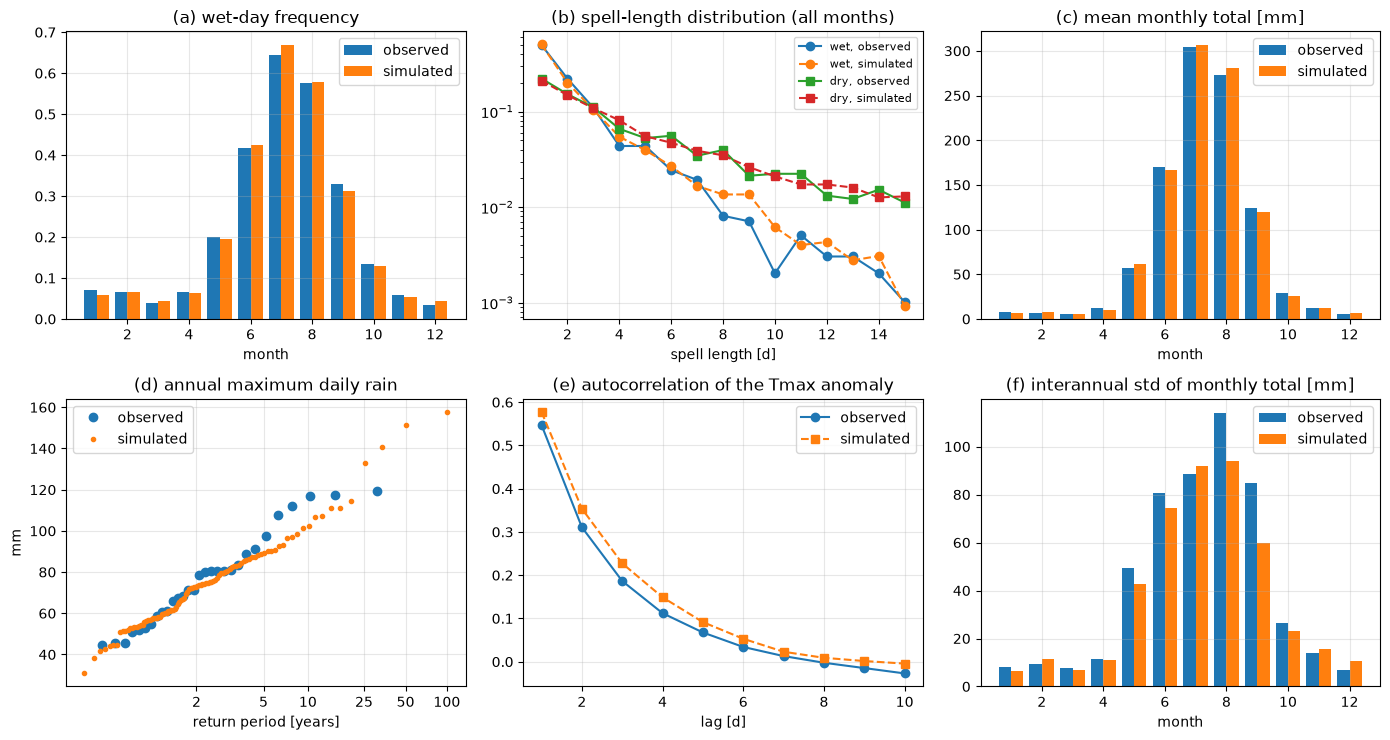

In [11]:
def acf_series(x, kmax=10):
    return np.array([np.corrcoef(x[k:], x[:-k])[0, 1] for k in range(1, kmax + 1)])


oy, sy = obs["year"].to_numpy() - 1, np.arange(NY * 365) // 365
ann_o = pd.Series(rain).groupby(oy).sum(); ann_s = pd.Series(sim["rain"]).groupby(sy).sum()
mon_o = pd.DataFrame({"y": oy, "m": month, "r": rain}).groupby(["y", "m"]).r.sum().unstack()
mon_s = pd.DataFrame({"y": sy, "m": sim["month"], "r": sim["rain"]}).groupby(["y", "m"]).r.sum().unstack()
w_o, d_o = spells(wet); w_s, d_s = spells(sim["wet"])

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
x12 = np.arange(1, 13)
ax = axes[0, 0]
ax.bar(x12 - 0.2, [wet[month == m].mean() for m in x12], 0.4, label="observed"); ax.bar(x12 + 0.2, [sim["wet"][sim["month"] == m].mean() for m in x12], 0.4, label="simulated")
ax.set_title("(a) wet-day frequency"); ax.set_xlabel("month"); ax.legend()
ax = axes[0, 1]
kk = np.arange(1, 16)
ax.semilogy(kk, [np.mean(w_o == i) for i in kk], "o-", label="wet, observed"); ax.semilogy(kk, [np.mean(w_s == i) for i in kk], "o--", label="wet, simulated")
ax.semilogy(kk, [np.mean(d_o == i) for i in kk], "s-", label="dry, observed"); ax.semilogy(kk, [np.mean(d_s == i) for i in kk], "s--", label="dry, simulated")
ax.set_title("(b) spell-length distribution (all months)"); ax.set_xlabel("spell length [d]"); ax.legend(fontsize=8)
ax = axes[0, 2]
ax.bar(x12 - 0.2, mon_o.mean(), 0.4, label="observed"); ax.bar(x12 + 0.2, mon_s.mean(), 0.4, label="simulated")
ax.set_title("(c) mean monthly total [mm]"); ax.set_xlabel("month"); ax.legend()
ax = axes[1, 0]                                   # extremes: annual maximum daily rain on a Gumbel scale
for nm, series, mk in (("observed", pd.Series(rain).groupby(oy).max(), "o"), ("simulated", pd.Series(sim["rain"]).groupby(sy).max(), ".")):
    v = np.sort(series.to_numpy()); Tret = (len(v) + 1) / (len(v) + 1 - np.arange(1, len(v) + 1))
    ax.plot(-np.log(-np.log(1 - 1 / Tret)), v, mk, label=nm)
ax.set_xticks(-np.log(-np.log(1 - 1 / np.array([2, 5, 10, 25, 50, 100])))); ax.set_xticklabels([2, 5, 10, 25, 50, 100])
ax.set_title("(d) annual maximum daily rain"); ax.set_xlabel("return period [years]"); ax.set_ylabel("mm"); ax.legend()
ax = axes[1, 1]
mon_anom = lambda x, mm: (pd.Series(x) - pd.Series(x).groupby(mm).transform("mean")).to_numpy()   # anomaly from the monthly mean
ax.plot(range(1, 11), acf_series(mon_anom(obs["tmax_c"].to_numpy(), month)), "o-", label="observed")
ax.plot(range(1, 11), acf_series(mon_anom(sim["tmax_c"], sim["month"])), "s--", label="simulated")
ax.set_title("(e) autocorrelation of the Tmax anomaly"); ax.set_xlabel("lag [d]"); ax.legend()
ax = axes[1, 2]
ax.bar(x12 - 0.2, mon_o.std(), 0.4, label="observed"); ax.bar(x12 + 0.2, mon_s.std(), 0.4, label="simulated")
ax.set_title("(f) interannual std of monthly total [mm]"); ax.set_xlabel("month"); ax.legend()
fig.tight_layout()

summ = pd.DataFrame({"observed (30 y)": [rain.sum() / 30, ann_o.std(), ann_o.std() / ann_o.mean(), w_o.mean(), d_o.mean(), np.percentile(rain, 99), rain.max()],
                     "simulated (100 y)": [sim["rain"].sum() / NY, ann_s.std(), ann_s.std() / ann_s.mean(), w_s.mean(), d_s.mean(), np.percentile(sim["rain"], 99), sim["rain"].max()]},
                    index=["mean annual rain [mm]", "std of annual rain [mm]", "CV of annual rain", "mean wet spell [d]", "mean dry spell [d]", "99th percentile of daily rain [mm]", "maximum daily rain [mm]"]).round(2)
display(summ)

**What the validation shows.** The quantities the generator is *built* to reproduce (wet-day frequency by month, mean monthly totals, spell lengths, the daily distribution of rain, the autocorrelation of temperature) agree closely; the simulated Tmax autocorrelation in panel (e) is slightly too high (lag 1: 0.58 against 0.55), a small price of describing the seasonal cycle by a single harmonic and constant wet/dry shifts, which leaves some seasonal structure in the anomalies. With real data one would test a second harmonic. The panel that does not agree is (f), and the table shows the same thing for the annual total: the **interannual variability is underestimated**, here by more than a third (a coefficient of variation of about 0.18 simulated against 0.28 observed). This is the best-known weakness of daily generators. Each day is drawn from parameters that are the same in every year, so the year-to-year differences of the monthly total are only what the daily randomness produces, whereas real years also differ because of slow influences (ENSO, the monsoon's strength, soil moisture) that the model does not contain. In the synthetic record we built that into the data on purpose by letting each year have a stronger or weaker monsoon.

The practical consequence is serious for water resources: droughts and floods lasting a season or a year are generated too rarely, and the risk of a multi-year shortfall in a reservoir is understated. The usual remedies are to make the parameters depend on a seasonal or annual covariate, or a low-frequency random factor (a "monsoon strength" drawn once a year), or to correct the monthly or annual variance afterwards. A generator should always be validated at the aggregation level that matters for the application; a generator that matches daily statistics need not match the annual ones.

**A validation checklist.** Compare observed and simulated series for: wet-day frequency; wet- and dry-spell length distributions; monthly and annual totals and their year-to-year variability; the daily rain distribution and extremes (annual maxima, high percentiles); the mean, standard deviation and autocorrelation of temperature; cross-correlations between variables; and the statistics of the *wet-day temperature difference*. Remember that the observed record is only 30 years, so differences within its own sampling uncertainty are not failures; repeat the observed-versus-simulated comparison with several 30-year simulated samples to see how much a single sample varies.

# 8) Downscaling: change factors on the parameters

With a validated generator, a future climate is represented by changing its parameters according to the **change factors** of a GCM or RCM: the ratio or difference of a statistic between a future and a control period (Lecture 18), computed *in the model* and then applied to the *observed* parameters. This keeps the model's bias out of the result, under the usual assumption that the bias is the same in both periods.

For each month:

- **Wet-day frequency and persistence.** The model gives a change in the stationary wet probability, $P_1\to f_{P}P_1$ (a multiplicative factor), and possibly in persistence, $\gamma\to\gamma+\Delta\gamma$. Using the relations from Section 4,
$$P_{01}'=P_1'(1-\gamma'),\qquad P_{11}'=P_{01}'+\gamma'.$$
(Lee and Singh work in logit and Fisher-$z$ space for the same step, which keeps probabilities inside $(0,1)$ automatically; the multiplicative form with a cap is simpler to explain and to put in a spreadsheet.)
- **Rain intensity.** The change in the wet-day mean and variance, $\bar x'=f_{m}\bar x$ and $s'^{2}=f_{v}s^{2}$, gives new gamma parameters
$$\alpha'=\frac{\bar x'^{2}}{s'^{2}},\qquad \beta'=\frac{s'^{2}}{\bar x'}.$$
If $f_v=f_m^{2}$ the coefficient of variation is unchanged and only the scale of the rain changes; $f_v>f_m^{2}$ makes the tail heavier.
- **Temperature and radiation.** The mean shifts, $\mu'=\mu+\Delta T$ (applied to the harmonic mean) and the standard deviation scales, $s'=f_s\,s$, while $\mathbf A$ and $\mathbf B$ are usually kept fixed, which assumes that the day-to-day dynamics do not change.

**An illustrative scenario.** We choose a warmer climate with fewer but heavier rain days and somewhat more persistent monsoon spells: $f_P=0.97$ in every month; $\Delta\gamma=+0.04$ in June&ndash;September; $f_m=1.12$ in the monsoon months and $1.06$ otherwise (of the order of the Clausius&ndash;Clapeyron rate of about 7 percent per K for a warming of 1.5 K; the extra in the monsoon is an assumption, not a projection); $f_v=1.10\,f_m^{2}$ (a slightly more variable amount); $\Delta T=+1.5$ $^\circ$C for Tmax and Tmin, no change in radiation or standard deviations. These numbers are **made up for the demonstration**; real factors would come from an ensemble of GCM/RCM runs for your region (Lectures 13 and 14), with their spread.

We simulate with the **same random numbers** as the baseline, so that all differences are caused by the parameters (common random numbers), and compute the same quantities as the validation table. Because the generator is simple, the main changes can also be computed analytically: mean annual rain is $\sum_{\text{months}}(\text{days})\,\pi_1\,\alpha\beta$, and the 99th percentile of *all* days solves $1-\pi_1+\pi_1F(x)=0.99$, that is $x_{99}=F^{-1}\!\big((0.99-1+\pi_1)/\pi_1;\alpha,\beta\big)$.

In [12]:
def apply_change(par, f_P1, d_gamma, f_mean, f_var, cap=0.95):
    """Monthly change factors -> perturbed generator parameters (arrays of 12)."""
    P01, P11 = par["P01"], par["P11"]
    P1 = stationary_wet(P01, P11); gam = P11 - P01
    mean = par["alpha"] * par["beta"]; var = par["alpha"] * par["beta"] ** 2
    P1n = np.minimum(f_P1 * P1, cap); gn = gam + d_gamma
    P01n = P1n * (1 - gn); P11n = P01n + gn
    mn, vn = mean * f_mean, var * f_var
    new = dict(par)
    new.update(P01=P01n, P11=P11n, alpha=mn ** 2 / vn, beta=vn / mn)
    return new


is_mon = np.isin(np.arange(1, 13), [6, 7, 8, 9])
f_P1 = np.full(12, 0.97)
d_gam = np.where(is_mon, 0.04, 0.0)
f_mean = np.where(is_mon, 1.12, 1.06)
f_var = np.round(1.10 * f_mean ** 2, 4)
dT = np.array([1.5, 1.5, 0.0])

par2 = apply_change(par, f_P1, d_gam, f_mean, f_var)
sim2 = simulate(par2, U100, change=dict(dT=dT, f_sd=1.0))      # same U100: common random numbers

# analytic statistics for the two parameter sets
def analytic(p):
    P1 = stationary_wet(p["P01"], p["P11"])
    mean = p["alpha"] * p["beta"]
    x99 = np.where(P1 > 0.01, gamma_dist.ppf(np.clip((0.99 - 1 + P1) / P1, 0, 1), p["alpha"], scale=p["beta"]), 0.0)
    return dict(P1=P1, total=MD * P1 * mean, wet_spell=1 / (1 - p["P11"]), dry_spell=1 / p["P01"], x99=x99)


an0, an2 = analytic(par), analytic(par2)
cf = pd.DataFrame({"P1 base": an0["P1"], "P1 scen": an2["P1"], "wet spell base [d]": an0["wet_spell"], "wet spell scen [d]": an2["wet_spell"],
                   "total base [mm]": an0["total"], "total scen [mm]": an2["total"], "x99 base [mm]": an0["x99"], "x99 scen [mm]": an2["x99"]},
                  index=range(1, 13)).round(2)
cf.index.name = "month"
display(cf)
print(f"analytic annual rain: baseline {an0['total'].sum():.0f} mm, scenario {an2['total'].sum():.0f} mm ({100*(an2['total'].sum()/an0['total'].sum()-1):+.1f} %)")

,P1 base,P1 scen,wet spell base [d],wet spell scen [d],total base [mm],total scen [mm],x99 base [mm],x99 scen [mm]
month,,,,,,,,
1,0.07,0.07,1.25,1.25,7.19,7.40,6.54,6.92
2,0.07,0.06,1.20,1.20,7.20,7.41,8.00,8.34
3,0.04,0.04,1.26,1.26,5.36,5.51,6.02,6.23
4,0.07,0.06,1.23,1.23,12.16,12.50,11.68,12.35
5,0.20,0.19,1.69,1.67,57.00,58.61,29.33,31.81
6,0.42,0.41,2.45,2.54,170.48,185.21,56.12,65.00
7,0.65,0.63,4.92,5.01,307.21,333.75,67.37,78.39
8,0.58,0.56,3.85,3.96,272.83,296.40,69.93,81.30
9,0.32,0.31,2.23,2.34,122.04,132.58,47.88,55.27


analytic annual rain: baseline 1008 mm, scenario 1087 mm (+7.9 %)


,baseline,scenario,change [%]
mean annual rain [mm],1009.65,1089.94,7.95
std of annual rain [mm],178.74,206.57,15.57
wet days per year,80.78,78.53,-2.79
"mean wet spell, all year [d]",2.49,2.53,1.57
"mean wet spell, Jun-Sep [d]",3.30,3.40,3.05
99th percentile of all days [mm],43.06,49.13,14.09
99th percentile of wet days [mm],72.05,84.27,16.96
mean annual maximum daily rain [mm],74.63,87.00,16.57
mean Tmax [C],32.37,33.89,4.68


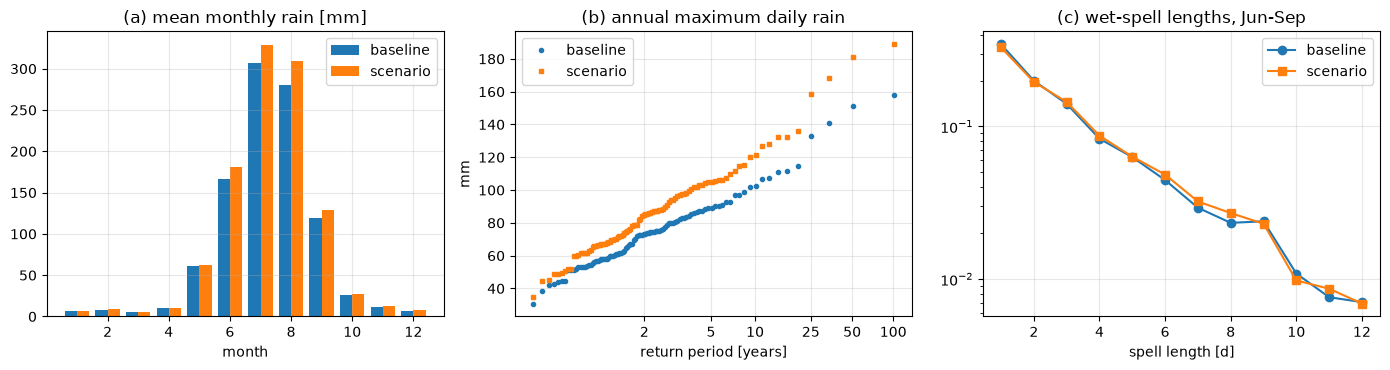

In [13]:
def jjas_spells(wetsim):
    """Wet-spell lengths inside June-September of each simulated year (day 152 to 273)."""
    out = []
    for yv in range(len(wetsim) // 365):
        seg = wetsim[yv * 365 + 151: yv * 365 + 273]
        out += list(spells(seg)[0])
    return np.array(out)


rows = {}
for nm, s_, p_ in (("baseline", sim, par), ("scenario", sim2, par2)):
    ann = pd.Series(s_["rain"]).groupby(sy).sum()
    w_, d_ = spells(s_["wet"]); wj = jjas_spells(s_["wet"])
    rows[nm] = [ann.mean(), ann.std(), s_["wet"].sum() / NY, w_.mean(), wj.mean(), np.percentile(s_["rain"], 99), np.percentile(s_["rain"][s_["rain"] > 0], 99),
                pd.Series(s_["rain"]).groupby(sy).max().mean(), s_["tmax_c"].mean()]
res = pd.DataFrame(rows, index=["mean annual rain [mm]", "std of annual rain [mm]", "wet days per year", "mean wet spell, all year [d]", "mean wet spell, Jun-Sep [d]",
                                "99th percentile of all days [mm]", "99th percentile of wet days [mm]", "mean annual maximum daily rain [mm]", "mean Tmax [C]"])
res["change [%]"] = 100 * (res["scenario"] / res["baseline"] - 1)
display(res.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ms = pd.DataFrame({"y": sy, "m": sim["month"], "r": sim["rain"]}).groupby("m").r.sum() / NY
ms2 = pd.DataFrame({"y": sy, "m": sim2["month"], "r": sim2["rain"]}).groupby("m").r.sum() / NY
axes[0].bar(x12 - 0.2, ms, 0.4, label="baseline"); axes[0].bar(x12 + 0.2, ms2, 0.4, label="scenario")
axes[0].set_title("(a) mean monthly rain [mm]"); axes[0].set_xlabel("month"); axes[0].legend()
for nm, s_, mk in (("baseline", sim, "o"), ("scenario", sim2, "s")):
    v = np.sort(pd.Series(s_["rain"]).groupby(sy).max().to_numpy()); Tret = (NY + 1) / (NY + 1 - np.arange(1, NY + 1))
    axes[1].plot(-np.log(-np.log(1 - 1 / Tret)), v, mk, ms=3, label=nm)
tt = np.array([2, 5, 10, 25, 50, 100]); axes[1].set_xticks(-np.log(-np.log(1 - 1 / tt))); axes[1].set_xticklabels(tt)
axes[1].set_title("(b) annual maximum daily rain"); axes[1].set_xlabel("return period [years]"); axes[1].set_ylabel("mm"); axes[1].legend()
kk = np.arange(1, 13)
axes[2].semilogy(kk, [np.mean(jjas_spells(sim["wet"]) == i) for i in kk], "o-", label="baseline")
axes[2].semilogy(kk, [np.mean(jjas_spells(sim2["wet"]) == i) for i in kk], "s-", label="scenario")
axes[2].set_title("(c) wet-spell lengths, Jun-Sep"); axes[2].set_xlabel("spell length [d]"); axes[2].legend()
fig.tight_layout();

**Reading the result.** The scenario has fewer wet days per year, slightly longer monsoon wet spells (the persistence term), a higher annual total and a markedly higher 99th percentile and annual maxima: rainfall becomes *more intense and more concentrated*. A delta change of the monthly mean (Lecture 14) could reproduce the increase in the annual total but not the fewer wet days, the longer spells or the change in the shape of the tail; those are what the generator adds. Two cautions. First, the weakness of Section 7 carries over: the year-to-year variability is still too small, so a drought or a flood season in the scenario is not represented realistically. Second, the result is only as credible as the change factors. Monthly change factors from a single GCM have large sampling uncertainty (Lecture 14), and a changing *wet-day frequency* is among the most uncertain pieces of information a climate model provides; always run several plausible sets.

# 9) The companion spreadsheet

The workbook `data/downscaling/lec21/lec21_worked_examples.xlsx` repeats the chain of calculations with live formulas, using the same synthetic data and the same **fixed** uniform random numbers (file `fixed_uniforms.csv`, also stored in the Data sheet). Because the random numbers never change, the sheet is reproducible, and changing a parameter or a change factor changes the result in a controlled way. Sheets: **README** (purpose, colour code), **Data** (inputs, helper columns, the uniform numbers), **AR1** (Section 2), **MAR1** (Section 3), **Markov** (Sections 4 and 5: counts to transition matrix, stationary distribution, spell lengths, gamma moments), **ChangeFactor** (Section 8: parameters and statistics recomputed) and **Simulate** (day-by-day generator for baseline and scenario, 5 years). The cell below runs the same calculation in Python, so you can compare the numbers with the sheet; blue cells are inputs, black are formulas.

In [14]:
U5 = uni[["u_occ", "u_amt", "u_e1", "u_e2", "u_e3"]].to_numpy()           # the 1825 fixed uniforms of the workbook (5 years)
s_b = simulate(par, U5)
s_s = simulate(par2, U5, change=dict(dT=dT, f_sd=1.0))
yrs = np.arange(1825) // 365
print("Markov sheet, July row:  P01 = %.4f  P11 = %.4f  P1 = %.4f  wet spell = %.3f d  dry spell = %.3f d" % (P01[6], P11[6], stationary_wet(P01[6], P11[6]), 1/(1-P11[6]), 1/P01[6]))
print("                         alpha = %.4f  beta = %.3f mm" % (alpha[6], beta[6]))
print("AR1 sheet:  phi = %.4f  sigma = %.4f  innovation sd = %.4f" % (phi_hat, sig_hat, sig_e_hat))
print("MAR1 sheet, A:\n", tf["A"].round(4))
print("\nSimulate sheet summary (5 simulated years with the fixed uniforms)        baseline   scenario")
for i in range(5):
    print(f"  annual rain, simulated year {i+1} (mm)                                   {s_b['rain'][yrs == i].sum():8.1f}   {s_s['rain'][yrs == i].sum():8.1f}")
wb_, ws_ = spells(s_b["wet"])[0], spells(s_s["wet"])[0]
print(f"  mean annual rain, simulated (mm)                                      {s_b['rain'].sum()/5:8.1f}   {s_s['rain'].sum()/5:8.1f}")
print(f"  mean annual rain, analytic (mm)                                       {an0['total'].sum():8.1f}   {an2['total'].sum():8.1f}")
print(f"  wet days per year                                                     {s_b['wet'].sum()/5:8.1f}   {s_s['wet'].sum()/5:8.1f}")
print(f"  number of wet spells / mean wet spell (d)                       {len(wb_):4d} {wb_.mean():6.2f}   {len(ws_):4d} {ws_.mean():6.2f}")
print(f"  99th percentile of daily rain (mm)                                    {np.percentile(s_b['rain'], 99):8.1f}   {np.percentile(s_s['rain'], 99):8.1f}")
print(f"  mean Tmax (C)                                                         {s_b['tmax_c'].mean():8.2f}   {s_s['tmax_c'].mean():8.2f}")

Markov sheet, July row:  P01 = 0.3776  P11 = 0.7970  P1 = 0.6503  wet spell = 4.925 d  dry spell = 2.648 d
                         alpha = 0.8867  beta = 17.187 mm
AR1 sheet:  phi = 0.5470  sigma = 2.2860  innovation sd = 1.9136
MAR1 sheet, A:
 [[ 0.5436  0.0914  0.0735]
 [ 0.1233  0.4981  0.0056]
 [ 0.0594 -0.0022  0.3813]]

Simulate sheet summary (5 simulated years with the fixed uniforms)        baseline   scenario
  annual rain, simulated year 1 (mm)                                     1182.3     1072.2
  annual rain, simulated year 2 (mm)                                      887.7      861.5
  annual rain, simulated year 3 (mm)                                      943.9      942.8
  annual rain, simulated year 4 (mm)                                     1093.0     1128.2
  annual rain, simulated year 5 (mm)                                      991.0     1064.2
  mean annual rain, simulated (mm)                                        1019.5     1013.8
  mean annual rain, analytic (

Five simulated years scatter around the analytic values (compare the simulated and analytic annual totals above and in the sheet), which is a good reminder of why we simulate 100 years in Section 7. In the workbook, try changing the **change factors** in the ChangeFactor sheet (yellow cells) and watch both the analytic table and the Simulate summary respond; set all factors to 1 and 0 and the scenario reproduces the baseline exactly.

# 10) The nonparametric (k-nearest-neighbour) weather generator

The parametric generator assumes distributions (gamma, normal), a chain order and linear dependence. The **k-nearest-neighbour (kNN) resampling generator** (Lall and Sharma, 1996; Rajagopalan and Lall, 1999) assumes none of this: it builds the synthetic series by *re-using observed days*, in an order chosen to respect the dependence on the previous day.

1. Describe a day by the vector $\mathbf x_t=(\text{rain},T_{\max},T_{\min},\dots)$.
2. To move from day $t$ to day $t+1$, take as candidates all observed days $j$ in **all years** whose calendar day lies within a window of $\pm w$ days of today's (this carries the season).
3. Compute the **Mahalanobis distance** of each candidate from today's vector, $D_j=(\mathbf x_t-\mathbf x_j)^{T}\mathbf C^{-1}(\mathbf x_t-\mathbf x_j)$, where $\mathbf C$ is the covariance matrix of the candidates; it removes the different units and the correlation among variables.
4. Keep the $K$ nearest candidates, with $K=\lfloor\sqrt{n_{\text{cand}}}\rfloor$ as a common rule of thumb, and pick one with the probability $p_m\propto 1/m$ for the $m$-th nearest, so that closer days are more likely.
5. The **successor** $\mathbf x_{j+1}$ of the chosen day becomes the new day $t+1$. Repeat.

**Why attractive.** The joint distribution and the correlations among variables, including the dependence of temperature on rain, come directly from the data, there is no distribution to fit, nonlinear and non-Gaussian behaviour is retained, and the method extends to many variables and to several sites at once (use the same chosen day for every site). **Limits.** It can only produce day-vectors that exist in the record: a rainfall extreme larger than any observed day, or a temperature beyond the observed range, can never appear, and every simulated day is a copy of an observed one, so it is a poor tool for design extremes. It also inherits the interannual-variability problem and, because it only perturbs the past, cannot by itself represent a changed climate; the future versions bias the choice of candidate years (for example towards warmer or drier years), but, as Lee and Singh note, the magnitude of the change then cannot be specified directly.

The cell below implements the algorithm for rain, Tmax and Tmin and compares it with the parametric generator.

In [15]:
def knn_generator(X, doy, n_years, window=7, seed=0):
    """kNN resampler. X: N x p observed daily vectors (365-day years, contiguous). Returns n_years*365 x p."""
    N, p = X.shape
    rng = np.random.default_rng(seed)
    pool, Cinv = {}, {}
    for d in range(1, 366):
        dist = np.abs(((doy - d + 182) % 365) - 182)                      # circular distance in days
        idx = np.flatnonzero((dist <= window) & (np.arange(N) < N - 1))   # a candidate needs a successor
        pool[d] = idx
        Cinv[d] = np.linalg.inv(np.cov(X[idx].T))
    out = np.empty((n_years * 365, p))
    x = X[rng.integers(N)]
    for t in range(n_years * 365):
        d = t % 365 + 1
        idx = pool[d]
        diff = X[idx] - x
        D = np.einsum("ij,jk,ik->i", diff, Cinv[d], diff)
        K = int(np.sqrt(len(idx)))
        order = np.argsort(D)[:K]
        w = 1.0 / np.arange(1, K + 1); w /= w.sum()
        pick = idx[order[rng.choice(K, p=w)]]
        x = X[pick + 1]                                                    # the successor day
        out[t] = x
    return out


Xobs = obs[["rain_mm", "tmax_c", "tmin_c"]].to_numpy()
knn = knn_generator(Xobs, doy, NY)
kw = (knn[:, 0] >= 0.1).astype(int)
ann_k = pd.Series(knn[:, 0]).groupby(np.arange(NY * 365) // 365).sum()
cmp_ = pd.DataFrame({
    "observed (30 y)": [wet.mean(), rain.sum() / 30, ann_o.std(), rain.max(), np.corrcoef(rain, Xobs[:, 1])[0, 1], Xobs[:, 1].max()],
    "parametric WG (100 y)": [sim["wet"].mean(), sim["rain"].sum() / NY, ann_s.std(), sim["rain"].max(), np.corrcoef(sim["rain"], sim["tmax_c"])[0, 1], sim["tmax_c"].max()],
    "kNN (100 y)": [kw.mean(), knn[:, 0].sum() / NY, ann_k.std(), knn[:, 0].max(), np.corrcoef(knn[:, 0], knn[:, 1])[0, 1], knn[:, 1].max()]},
    index=["wet-day fraction", "mean annual rain [mm]", "std of annual rain [mm]", "maximum daily rain [mm]", "correlation rain-Tmax", "maximum Tmax [C]"]).round(3)
display(cmp_)

,observed (30 y),parametric WG (100 y),kNN (100 y)
wet-day fraction,0.221,0.221,0.218
mean annual rain [mm],1006.823,1009.651,1019.531
std of annual rain [mm],285.355,178.740,201.962
maximum daily rain [mm],119.200,157.757,119.200
correlation rain-Tmax,-0.134,-0.148,-0.138
maximum Tmax [C],45.400,46.783,45.400


The kNN series keeps the rain&ndash;temperature relation (the correlation comes directly from the data) and reproduces the wet-day fraction, but its maximum daily rain and maximum Tmax are bounded by the observed values, while the parametric generator, whose gamma tail is unbounded, produces larger extremes over 100 years. Which is more credible depends on the question: for the typical weather the kNN generator is excellent; for the 100-year design rainfall, the observed range is a limitation (and the parametric tail a model assumption). Both underestimate the year-to-year variability of the annual total.

# Summary

- A **weather generator** is a fitted stochastic model of daily weather at a site. It produces unlimited synthetic series with the observed statistics, and, with perturbed parameters, a **downscaled** future climate that can change wet-day frequency, persistence and intensity, which a delta change cannot.
- **AR(1)**: $a_t=\phi a_{t-1}+\varepsilon_t$ has $\sigma_a^2=\sigma_\varepsilon^2/(1-\phi^2)$ and $\rho_k=\phi^k$; $\hat\phi$ is the lag-1 autocorrelation. The **multivariate AR(1)** $\mathbf y_t=\mathbf A\mathbf y_{t-1}+\mathbf B\mathbf e_t$ has $\mathbf A=\mathbf M_1\mathbf M_0^{-1}$ and $\mathbf B\mathbf B^T=\mathbf M_0-\mathbf A\mathbf M_1^T$, with $\mathbf B$ the Cholesky factor.
- The **two-state Markov chain** has maximum-likelihood estimates $\hat P_{01}=N_{01}/N_0$, $\hat P_{11}=N_{11}/N_1$, stationary wet probability $P_{01}/(P_{01}+1-P_{11})$ and geometric spells with means $1/(1-P_{11})$ (wet) and $1/P_{01}$ (dry). Real spells are more variable, which motivates higher-order or mixed models.
- **Amounts** on wet days are gamma, $\alpha=\bar x^2/s^2$, $\beta=s^2/\bar x$, sampled by the inverse transform. The **WGEN structure** is occurrence, then amount, then temperature and radiation conditioned on the wet or dry state, with monthly parameters and harmonic seasonal means.
- **Downscaling** changes the parameters: $P_1$ and $\gamma$ for occurrence, the gamma mean and variance for intensity, the mean and standard deviation of temperature.
- **Validate** against wet-day frequency, spells, monthly totals, extremes and autocorrelation. The **interannual variability is typically underestimated**.
- The **kNN generator** resamples observed days and keeps the joint distribution without assumptions, but cannot exceed the observed range.

# Check your understanding

1. An AR(1) anomaly has $\phi=0.8$ and the daily innovations have a standard deviation of $1.2\,^\circ$C. What are the standard deviation of the anomaly, the lag-3 autocorrelation and the e-folding time? What happens to the variance of the anomaly if $\phi$ is increased to 0.95 at fixed $\sigma_\varepsilon$?
2. In a given month the counts are $N_{00}=120$, $N_{01}=30$, $N_{10}=25$ and $N_{11}=45$. Compute $\hat P_{01}$, $\hat P_{11}$, the stationary wet probability, and the mean wet and dry spell lengths. Show that the wet fraction implied by the spells equals the stationary probability.
3. Why can the lower-triangular Cholesky factor of $\mathbf D$ be used to generate correlated noise, and why must $\mathbf D$ be positive definite? What goes wrong if one simulates the three variables as independent AR(1) processes?
4. A generator reproduces the monthly mean rainfall, the wet-day frequency and the spell lengths of the record, but the standard deviation of the annual total is 35 percent too small. Give two physical reasons and one practical consequence for reservoir design.
5. A GCM projects a 10 percent increase in the mean rain on wet days and a 3 percent decrease in the wet-day frequency in July. Which parameters of the generator would you change, and by how much does the mean July rain change? What does a delta change of $+7$ percent on the monthly mean not capture?

# Try it yourself

- In Section 7 change the seed of `U100` and the number of years (10, 30, 100, 500). How variable are the standard deviation of the annual total and the 99th percentile for 30-year samples?
- Fit the occurrence chain with the wet-day threshold 1 mm instead of 0.1 mm (the threshold is in the data-loading cell, `wet = (rain >= 0.1)`, and in cell B3 of the Markov sheet) and see which parameters change.
- In Section 8 set $\Delta\gamma=0$ and $f_P=1$ and change only the gamma factors; then do the reverse. Which part of the rain extreme comes from intensity and which from frequency?
- Make the interannual variability realistic: draw one random number per year, $\eta\sim N(0,0.35^2)$, add it to the logit of $P_{01}$ and $P_{11}$ in the simulation loop and see how the std of the annual totals changes.
- In the kNN generator try windows of 3 and 15 days. How do the autocorrelation of Tmax and the wet-day fraction change?
- Open the workbook and change the month in the Markov sheet (cell B21) to see how the spell-length distribution changes between the dry season and the monsoon.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The method follows Lee, T., & Singh, V. P. (2019), *Statistical Downscaling for Hydrological and Environmental Applications*, CRC Press, **Chapter 6** (Sections 6.1 mathematical background, 6.2 the weather generator including fitting, simulation and implementation of downscaling, 6.3 the nonparametric weather generator). The derivations, the synthetic data, the code and the figures are our own; the numerical examples of the book are not reproduced.

**Method papers.** Richardson, C. W. (1981). Stochastic simulation of daily precipitation, temperature, and solar radiation. *Water Resources Research, 17*(1), 182&ndash;190. &middot; Richardson, C. W., & Wright, D. A. (1984). *WGEN: A model for generating daily weather variables*. USDA Agricultural Research Service, ARS-8. &middot; Matalas, N. C. (1967). Mathematical assessment of synthetic hydrology. *Water Resources Research, 3*(4), 937&ndash;945 (the multivariate AR(1) moment equations). &middot; Lall, U., & Sharma, A. (1996). A nearest neighbor bootstrap for resampling hydrologic time series. *Water Resources Research, 32*(3), 679&ndash;691. &middot; Rajagopalan, B., & Lall, U. (1999). A k-nearest-neighbor simulator for daily precipitation and other weather variables. *Water Resources Research, 35*(10), 3089&ndash;3101.

**Data.** The daily record in `data/downscaling/lec21/obs_daily_synthetic.csv` and the fixed uniform numbers in `fixed_uniforms.csv` are **synthetic** and were generated for this lecture; they do not describe any station. The companion workbook `lec21_worked_examples.xlsx` uses the same files. Change factors in Section 8 are illustrative, not projections.
```